In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.layers import BatchNormalization 

In [3]:
from PIL import Image, UnidentifiedImageError
data_dir = r'C:\Users\Tarek Mamdouh\Documents\Downloads\PlantVillage' 
# إعداد المتغيرات
img_size = 128   # حجم الصور الجديد
images = []
labels = []

# قراءة الصور
for category in os.listdir(data_dir):
    category_path = os.path.join(data_dir, category)
    label = os.listdir(data_dir).index(category)  # نعطي لكل فئة رقمًا

    for img_name in os.listdir(category_path):
        img_path = os.path.join(category_path, img_name)
        try:
            img = load_img(img_path, target_size=(img_size, img_size))  # تغيير حجم الصورة
            img_array = img_to_array(img) / 255.0  # تطبيع القيم بين 0 و 1
            images.append(img_array)
            labels.append(label)
        except UnidentifiedImageError:
            print(f"Skipped invalid image file: {img_path}")

# تحويل القوائم إلى مصفوفات NumPy
images = np.array(images)
labels = np.array(labels)

print(f"Total valid images: {len(images)}")
print(f"Total labels: {len(labels)}")


Skipped invalid image file: C:\Users\Tarek Mamdouh\Documents\Downloads\PlantVillage\Tomato__Tomato_YellowLeaf__Curl_Virus\svn-r6Yb5c
Total valid images: 20638
Total labels: 20638


In [4]:
# تقسيم البيانات
x_train, x_test, y_train, y_test = train_test_split(images, labels, test_size=0.2, random_state=42)

# تحويل التسميات إلى one-hot encoding
num_classes = len(set(labels))
y_train = to_categorical(y_train, num_classes)
y_test = to_categorical(y_test, num_classes)

In [5]:
x_train = np.array(x_train)
y_train = np.array(y_train)

In [6]:
print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")

x_train shape: (16510, 128, 128, 3)
y_train shape: (16510, 15)


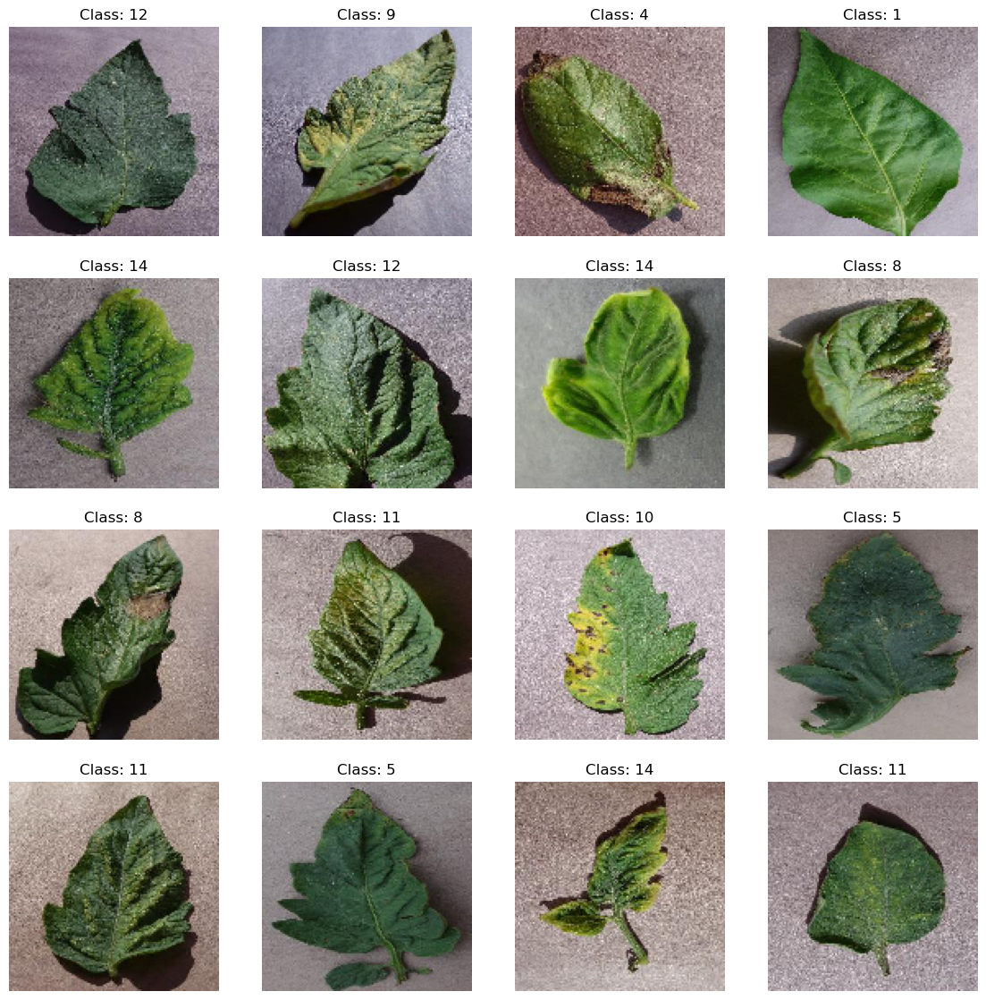

In [7]:
# عرض عينة من الصور
plt.figure(figsize=(14, 14))
for i in range(16):
    plt.subplot(4, 4, i+1)
    plt.imshow(x_train[i])
    plt.title(f"Class: {np.argmax(y_train[i])}")
    plt.axis('off')
plt.show()


# The First Model

In [8]:
nn_model = Sequential([ 
    Flatten(input_shape=(img_size, img_size, 3)),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),  
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),
    Dense(256, activation='relu'), 
    BatchNormalization(),
    Dropout(0.4),
    Dense(256, activation='relu'), 
    BatchNormalization(),
    Dropout(0.4),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),
    Dense(64, activation='relu'), 
    BatchNormalization(),
    Dropout(0.4),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.4),
    Dense(num_classes, activation='softmax') 
])

F:\anaconda\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [9]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)

# قائمة الـ Callbacks
callbacks = [early_stop, checkpoint]

In [10]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# التأكد من أن x_train و y_train متطابقين في الطول
print(f"Length of x_train: {len(x_train)}")
print(f"Length of y_train: {len(y_train)}")

# إنشاء المولد
train_generator = datagen.flow(x_train, y_train)


Length of x_train: 16510
Length of y_train: 16510


In [11]:
x_test = np.array(x_train)
y_test = np.array(y_train)

In [12]:
print(x_test.shape)
print(y_test.shape)

(16510, 128, 128, 3)
(16510, 15)


In [13]:
nn_model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

In [14]:
nn_history = nn_model.fit(
    train_generator,  # استخدام Augmentation
    epochs=100,
    validation_data=(x_test, y_test),
    callbacks=callbacks,  # إضافة Early Stopping و Checkpoint
    batch_size= 8 # تعديل Batch Size
)

F:\anaconda\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 139s 246ms/step - accuracy: 0.0958 - loss: 3.3404 - val_accuracy: 0.1939 - val_loss: 2.4068
Epoch 2/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 119s 229ms/step - accuracy: 0.1495 - loss: 2.6460 - val_accuracy: 0.2213 - val_loss: 2.2851
Epoch 3/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 113s 220ms/step - accuracy: 0.1955 - loss: 2.4276 - val_accuracy: 0.1968 - val_loss: 2.7622
Epoch 4/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 115s 223ms/step - accuracy: 0.2798 - loss: 2.2075 - val_accuracy: 0.3735 - val_loss: 1.9567
Epoch 5/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 125s 242ms/step - accuracy: 0.3226 - loss: 2.0839 - val_accuracy: 0.3752 - val_loss: 1.9134
Epoch 6/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 119s 231ms/step - accuracy: 0.3581 - loss: 2.0122 - val_accuracy: 0.4286 - val_loss: 1.8041
Epoch 7/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 135s 217ms/step - accuracy: 0.3685 - loss: 1.9778 - val_accuracy: 0.3341 - val_loss: 2.0472
Epoch 8/100
516/516 ━━━━━━━━━━━━━━━━━━━━ 117s 227ms/step - accuracy: 

In [15]:
# تقييم النموذج على بيانات الاختبار
test_loss, test_accuracy = nn_model.evaluate(x_test, y_test)
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

516/516 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.4964 - loss: 1.5514
Test Loss: 1.5440651178359985
Test Accuracy: 0.49733495712280273


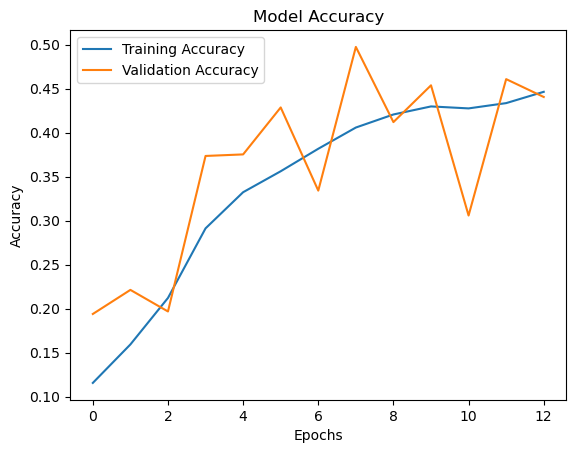

In [16]:
plt.plot(nn_history.history['accuracy'], label='Training Accuracy')
plt.plot(nn_history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

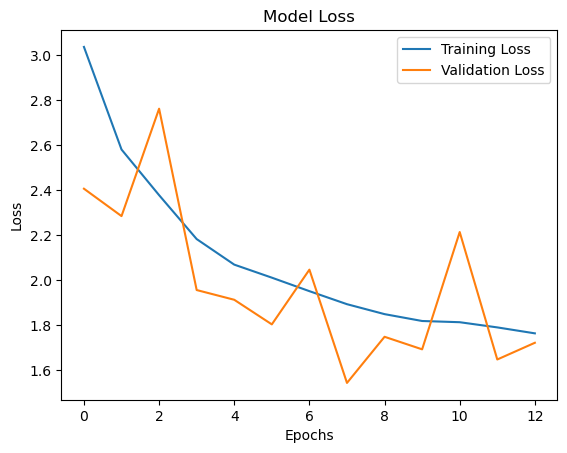

In [17]:
plt.plot(nn_history.history['loss'], label='Training Loss')
plt.plot(nn_history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

In [18]:
random_idx = np.random.randint(0, len(x_test))
sample = x_test[random_idx]
true_label = np.argmax(y_test[random_idx])

In [19]:
predicted_label = np.argmax(nn_model.predict(np.expand_dims(sample, axis=0)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


In [20]:
print(f"True Label: {true_label}, Predicted Label: {predicted_label}")

True Label: 14, Predicted Label: 14


In [21]:
nn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 49152)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 256)                 │      12,583,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 38,750,767 (147.82 MB)

 Trainable params: 12,915,727 (49.27 MB)

 Non-trainable params: 3,584 (14.00 KB)

 Optimizer params: 25,831,456 (98.54 MB)

In [22]:
# الحصول على التوقعات الاحتمالية
y_pred_proba = nn_model.predict(x_test)  

# تحويل التوقعات الاحتمالية إلى قيم ثنائية (0 أو 1) أو القيم الفئوية
y_pred = np.argmax(y_pred_proba, axis=1)  # إذا كان لديك تصنيفات متعددة
y_true = np.argmax(y_test, axis=1)  #

516/516 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step


In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted') 
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [24]:
print("Evaluation Metrics:")
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-Score: {f1:.2f}") 

Evaluation Metrics:
Accuracy: 0.50
Precision: 0.42
Recall: 0.50
F1-Score: 0.42


In [25]:
print("\nClassification Report:")
print(classification_report(y_true, y_pred)) 


Classification Report:
              precision    recall  f1-score   support

           0       0.32      0.03      0.06       818
           1       0.46      0.83      0.59      1207
           2       0.69      0.63      0.66       784
           3       0.00      0.00      0.00       113
           4       0.17      0.00      0.00       787
           5       0.46      0.75      0.57      1704
           6       0.00      0.00      0.00       800
           7       0.64      0.84      0.73      1264
           8       0.44      0.53      0.48      1519
           9       0.27      0.06      0.09       781
          10       0.34      0.03      0.05      1449
          11       0.39      0.58      0.47      1348
          12       0.54      0.39      0.45      1078
          13       0.00      0.00      0.00       295
          14       0.53      0.88      0.67      2563

    accuracy                           0.50     16510
   macro avg       0.35      0.37      0.32     16510
we

F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


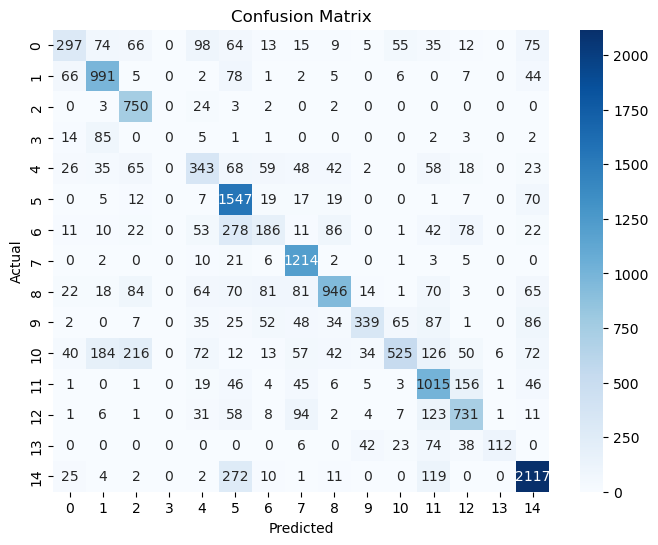

In [49]:
 import seaborn as sns
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=range(num_classes), yticklabels=range(num_classes))
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


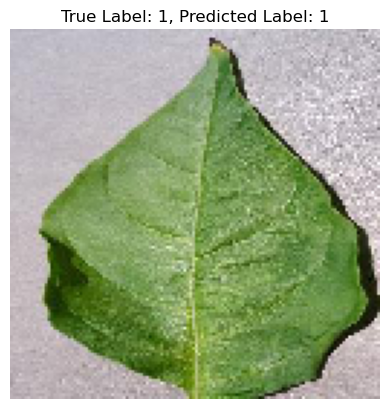

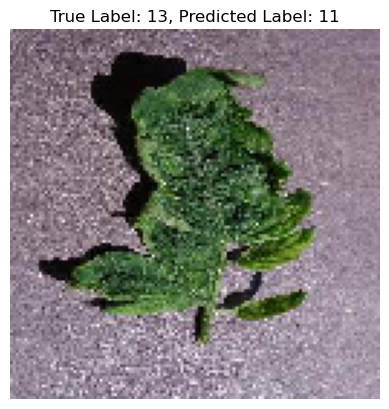

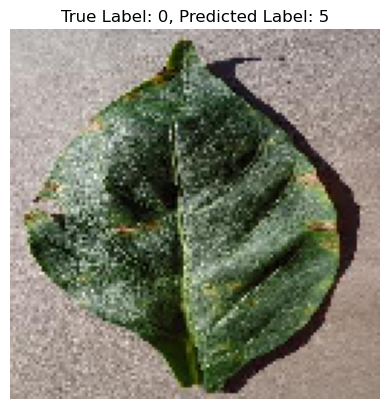

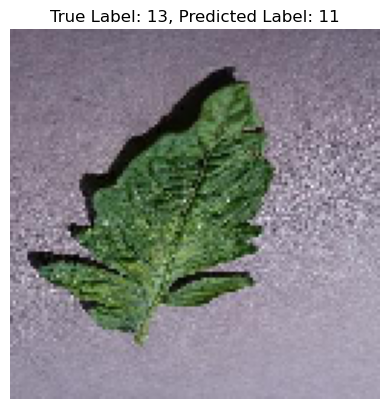

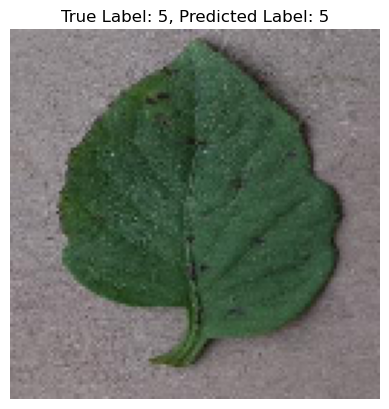

...

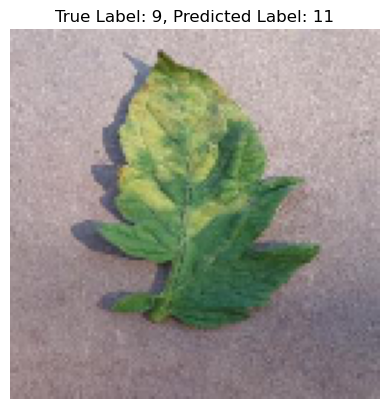

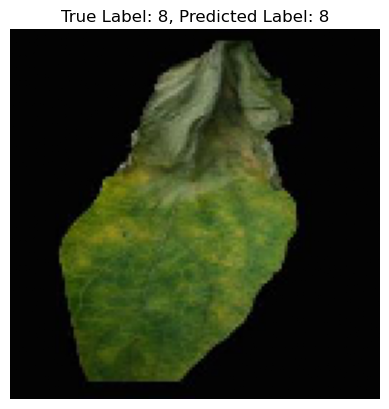

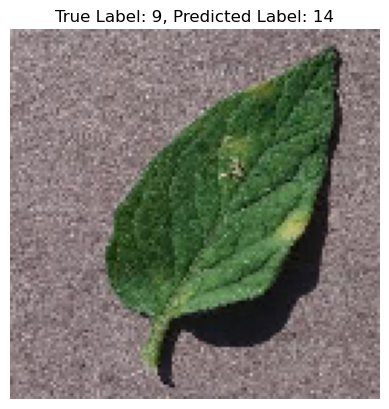

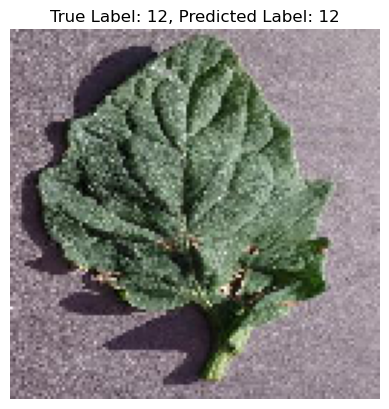

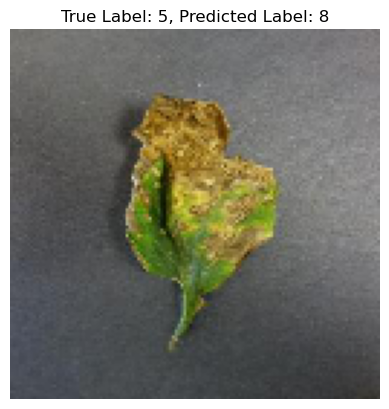

In [27]:
# عدد الصور التي تريد عرضها
num_images_to_display = 15

# اختيار عينات عشوائية من مجموعة الاختبار
random_indices = np.random.choice(len(x_test), num_images_to_display, replace=False)

# التنبؤ باستخدام النموذج
predictions = nn_model.predict(x_test[random_indices])

# عرض الصور مع الفئات الحقيقية والمتوقعة
for i, idx in enumerate(random_indices):
    sample = x_test[idx]
    true_label = np.argmax(y_test[idx])  # إذا كان y_test في صيغة one-hot encoding
    predicted_label = np.argmax(predictions[i])

    # عرض الصورة
    plt.imshow(sample)
    plt.title(f"True Label: {true_label}, Predicted Label: {predicted_label}")
    plt.axis('off')  # إخفاء المحاور
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


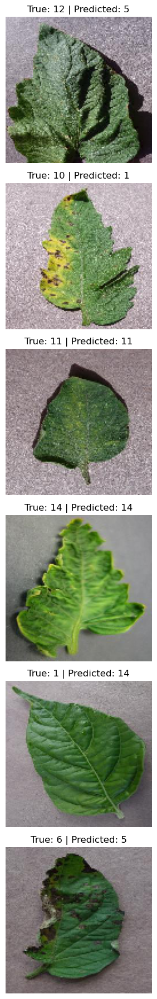

In [29]:
# اختيار إدخالات يدوية (أرقام الصور في x_test)
input_indices = [5, 10,15,20,25,30]  # ضع هنا أرقام الصور التي تريد عرضها

# التحقق من صحة المدخلات
for idx in input_indices:
    if idx >= len(x_test):
        print(f"Index {idx} is out of range! The dataset contains {len(x_test)} samples.")
        exit()

# التنبؤ باستخدام النموذج
predictions = nn_model.predict(x_test[input_indices])

# عرض الصور مع الفئات الحقيقية والفئات المتوقعة
plt.figure(figsize=(10, len(input_indices) * 3))
for i, idx in enumerate(input_indices):
    sample = x_test[idx]
    true_label = np.argmax(y_test[idx])  # إذا كان y_test في صيغة one-hot encoding
    predicted_label = np.argmax(predictions[i])

    # عرض الصورة
    plt.subplot(len(input_indices), 1, i + 1)  # ترتيب الصور في شبكة عمودية
    plt.imshow(sample)
    plt.title(f"True: {true_label} | Predicted: {predicted_label}")
    plt.axis('off')  # إخفاء المحاور

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


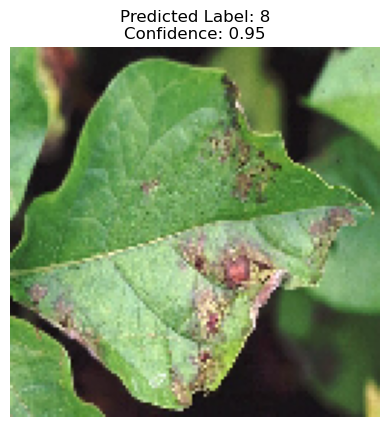

In [56]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# تحديد مسار الصورة التي تريد اختبارها
image_path = r'Unidentified_disease_on_potato_leaf.jpg'  # عدّل هذا المسار حسب مكان الصورة على جهازك

# إعداد الحجم المطلوب للصورة (يجب أن يتطابق مع حجم الإدخال للنموذج)
img_size = 128  # أو أي حجم حددته في نموذجك

# تحميل الصورة وتغيير حجمها
try:
    img = load_img(image_path, target_size=(img_size, img_size))  # تحميل الصورة بالحجم المناسب
    img_array = img_to_array(img) / 255.0  # تحويل الصورة إلى مصفوفة وتطبيع القيم إلى [0, 1]

    # إضافة بُعد إضافي لجعلها في صيغة (1, img_size, img_size, 3)
    img_array = np.expand_dims(img_array, axis=0)

    # التنبؤ باستخدام النموذج
    prediction = nn_model.predict(img_array)
    predicted_label = np.argmax(prediction)  # اختيار التصنيف الأكثر احتمالاً
    confidence = np.max(prediction)  # درجة الثقة في التوقع

    # عرض الصورة مع الفئة المتوقعة
    plt.imshow(img)
    plt.title(f"Predicted Label: {predicted_label}\nConfidence: {confidence:.2f}")
    plt.axis('off')
    plt.show()

except Exception as e:
    print(f"Error loading or processing image: {e}")

# The Seconde Model 

In [32]:
nn_model = Sequential([ 
    Flatten(input_shape=(img_size, img_size, 3)),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),  
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(128, activation='relu'), 
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation='relu'), 
    BatchNormalization(),
    Dropout(0.3),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),
    Dense(num_classes, activation='softmax') 
])

F:\anaconda\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [33]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)

# قائمة الـ Callbacks
callbacks = [early_stop, checkpoint]

In [34]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# التأكد من أن x_train و y_train متطابقين في الطول
print(f"Length of x_train: {len(x_train)}")
print(f"Length of y_train: {len(y_train)}")

# إنشاء المولد
train_generator = datagen.flow(x_train, y_train)

Length of x_train: 16510
Length of y_train: 16510


In [35]:
nn_model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

In [36]:
nn_history = nn_model.fit(
    train_generator,  # استخدام Augmentation
    epochs=20,
    validation_data=(x_test, y_test),
    callbacks=callbacks,  # إضافة Early Stopping و Checkpoint
    batch_size= 14 # تعديل Batch Size
)

F:\anaconda\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 145s 262ms/step - accuracy: 0.1588 - loss: 2.9076 - val_accuracy: 0.2376 - val_loss: 2.4922
Epoch 2/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 129s 248ms/step - accuracy: 0.3459 - loss: 2.0976 - val_accuracy: 0.4302 - val_loss: 1.7614
Epoch 3/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 111s 214ms/step - accuracy: 0.4106 - loss: 1.8800 - val_accuracy: 0.2919 - val_loss: 2.2265
Epoch 4/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 112s 216ms/step - accuracy: 0.4300 - loss: 1.7997 - val_accuracy: 0.3987 - val_loss: 1.9161
Epoch 5/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 109s 210ms/step - accuracy: 0.4653 - loss: 1.7005 - val_accuracy: 0.2942 - val_loss: 2.0999
Epoch 6/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 110s 213ms/step - accuracy: 0.4730 - loss: 1.6727 - val_accuracy: 0.3990 - val_loss: 1.8265
Epoch 7/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 116s 225ms/step - accuracy: 0.4820 - loss: 1.6486 - val_accuracy: 0.4800 - val_loss: 1.6522
Epoch 8/20
516/516 ━━━━━━━━━━━━━━━━━━━━ 122s 236ms/step - accuracy: 0.4950 -

In [37]:
# تقييم النموذج على بيانات الاختبار
test_loss, test_accuracy = nn_model.evaluate(x_test, y_test)
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

516/516 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.6754 - loss: 0.9973
Test Loss: 0.9979243278503418
Test Accuracy: 0.6731072068214417


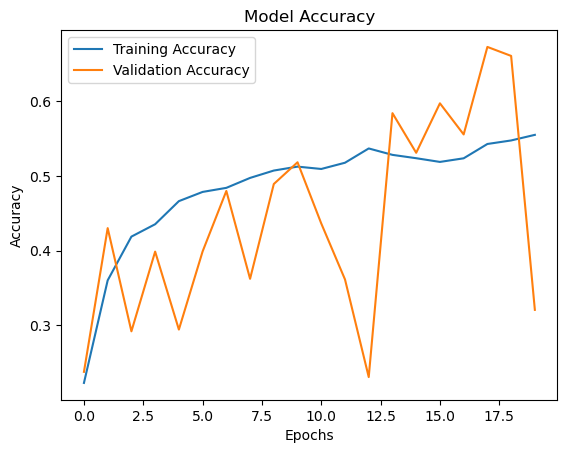

In [38]:
plt.plot(nn_history.history['accuracy'], label='Training Accuracy')
plt.plot(nn_history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

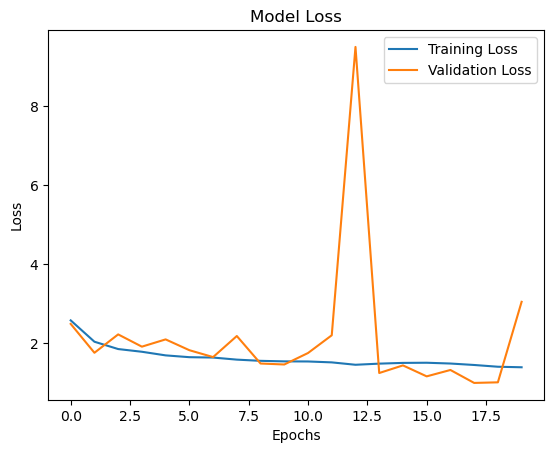

In [39]:
plt.plot(nn_history.history['loss'], label='Training Loss')
plt.plot(nn_history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

In [40]:
andom_idx = np.random.randint(0, len(x_test))
sample = x_test[random_idx]
true_label = np.argmax(y_test[random_idx])

In [41]:
predicted_label = np.argmax(nn_model.predict(np.expand_dims(sample, axis=0)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 870ms/step


In [42]:
print(f"True Label: {true_label}, Predicted Label: {predicted_label}")

True Label: 14, Predicted Label: 14


In [43]:
nn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 49152)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 256)                 │      12,583,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_9                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_9 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_10               │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_10 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_12 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_11               │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_11 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_13 (Dense)                     │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_12               │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_12 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_14 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_13               │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_13 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_14               │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 38,142,447 (145.50 MB)

 Trainable params: 12,713,551 (48.50 MB)

 Non-trainable params: 1,792 (7.00 KB)

 Optimizer params: 25,427,104 (97.00 MB)

In [44]:
# الحصول على التوقعات الاحتمالية
y_pred_proba = nn_model.predict(x_test)  

# تحويل التوقعات الاحتمالية إلى قيم ثنائية (0 أو 1) أو القيم الفئوية
y_pred = np.argmax(y_pred_proba, axis=1)  # إذا كان لديك تصنيفات متعددة
y_true = np.argmax(y_test, axis=1) 

516/516 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step


In [45]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted') 
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [46]:
print("Evaluation Metrics:")
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-Score: {f1:.2f}") 

Evaluation Metrics:
Accuracy: 0.67
Precision: 0.68
Recall: 0.67
F1-Score: 0.65


In [47]:
print("\nClassification Report:")
print(classification_report(y_true, y_pred)) 


Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.36      0.45       818
           1       0.70      0.82      0.76      1207
           2       0.61      0.96      0.74       784
           3       0.00      0.00      0.00       113
           4       0.45      0.44      0.44       787
           5       0.61      0.91      0.73      1704
           6       0.41      0.23      0.30       800
           7       0.74      0.96      0.84      1264
           8       0.78      0.62      0.69      1519
           9       0.76      0.43      0.55       781
          10       0.76      0.36      0.49      1449
          11       0.58      0.75      0.65      1348
          12       0.66      0.68      0.67      1078
          13       0.93      0.38      0.54       295
          14       0.80      0.83      0.81      2563

    accuracy                           0.67     16510
   macro avg       0.63      0.58      0.58     16510
we

F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


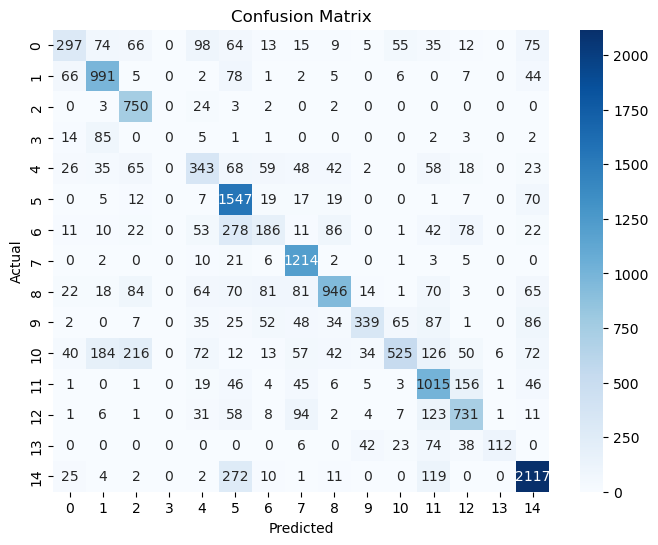

In [50]:
import seaborn as sns
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=range(num_classes), yticklabels=range(num_classes))
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step


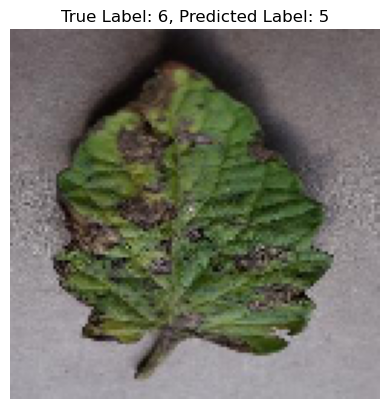

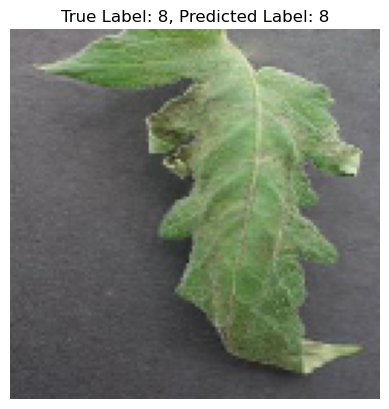

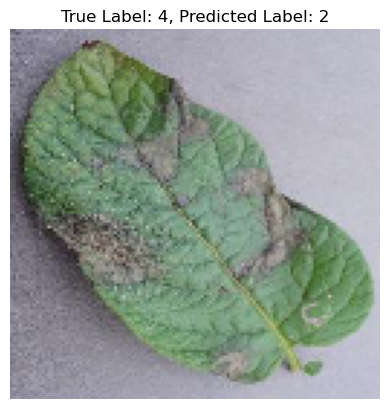

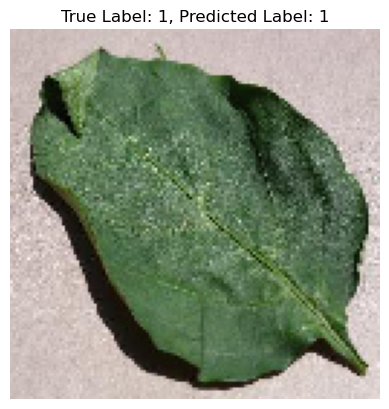

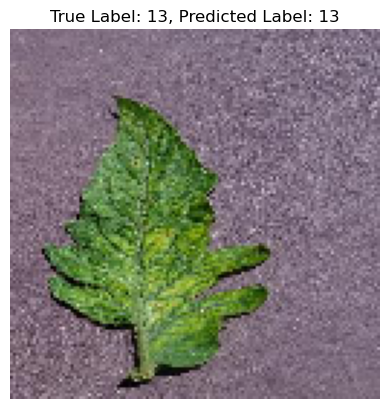

...

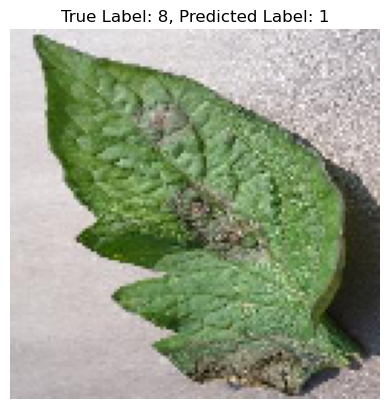

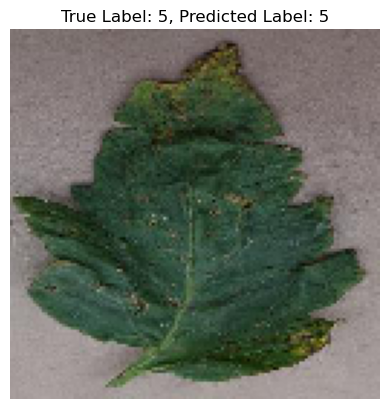

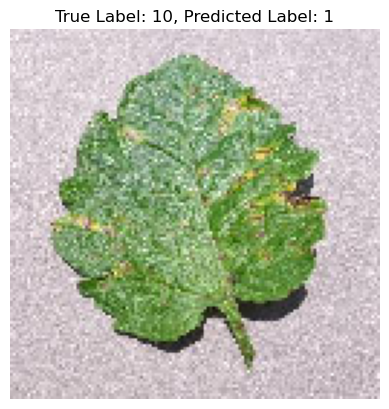

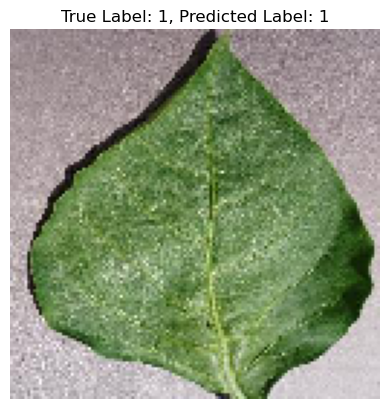

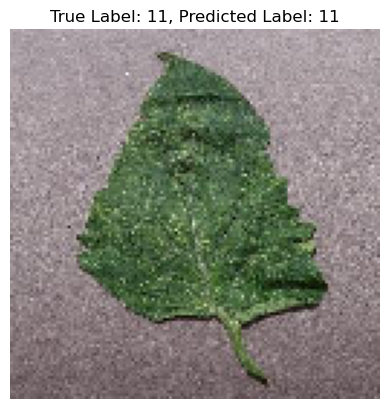

In [51]:
# عدد الصور التي تريد عرضها
num_images_to_display = 15

# اختيار عينات عشوائية من مجموعة الاختبار
random_indices = np.random.choice(len(x_test), num_images_to_display, replace=False)

# التنبؤ باستخدام النموذج
predictions = nn_model.predict(x_test[random_indices])

# عرض الصور مع الفئات الحقيقية والمتوقعة
for i, idx in enumerate(random_indices):
    sample = x_test[idx]
    true_label = np.argmax(y_test[idx])  # إذا كان y_test في صيغة one-hot encoding
    predicted_label = np.argmax(predictions[i])

    # عرض الصورة
    plt.imshow(sample)
    plt.title(f"True Label: {true_label}, Predicted Label: {predicted_label}")
    plt.axis('off')  # إخفاء المحاور
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


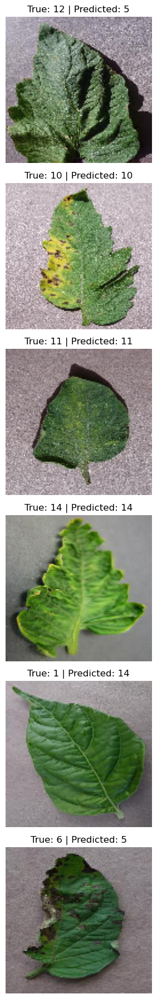

In [52]:
# اختيار إدخالات يدوية (أرقام الصور في x_test)
input_indices = [5, 10,15,20,25,30]  # ضع هنا أرقام الصور التي تريد عرضها

# التحقق من صحة المدخلات
for idx in input_indices:
    if idx >= len(x_test):
        print(f"Index {idx} is out of range! The dataset contains {len(x_test)} samples.")
        exit()

# التنبؤ باستخدام النموذج
predictions = nn_model.predict(x_test[input_indices])

# عرض الصور مع الفئات الحقيقية والفئات المتوقعة
plt.figure(figsize=(10, len(input_indices) * 3))
for i, idx in enumerate(input_indices):
    sample = x_test[idx]
    true_label = np.argmax(y_test[idx])  # إذا كان y_test في صيغة one-hot encoding
    predicted_label = np.argmax(predictions[i])

    # عرض الصورة
    plt.subplot(len(input_indices), 1, i + 1)  # ترتيب الصور في شبكة عمودية
    plt.imshow(sample)
    plt.title(f"True: {true_label} | Predicted: {predicted_label}")
    plt.axis('off')  # إخفاء المحاور

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step


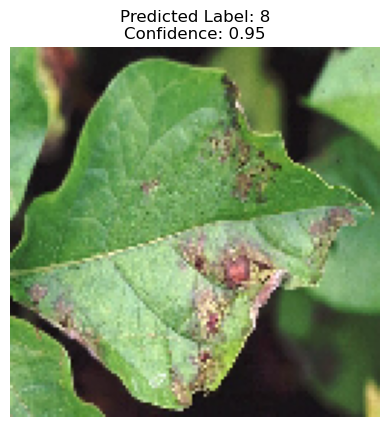

In [55]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# تحديد مسار الصورة التي تريد اختبارها
image_path = r'Unidentified_disease_on_potato_leaf.jpg'  # عدّل هذا المسار حسب مكان الصورة على جهازك

# إعداد الحجم المطلوب للصورة (يجب أن يتطابق مع حجم الإدخال للنموذج)
img_size = 128  # أو أي حجم حددته في نموذجك

# تحميل الصورة وتغيير حجمها
try:
    img = load_img(image_path, target_size=(img_size, img_size))  # تحميل الصورة بالحجم المناسب
    img_array = img_to_array(img) / 255.0  # تحويل الصورة إلى مصفوفة وتطبيع القيم إلى [0, 1]

    # إضافة بُعد إضافي لجعلها في صيغة (1, img_size, img_size, 3)
    img_array = np.expand_dims(img_array, axis=0)

    # التنبؤ باستخدام النموذج
    prediction = nn_model.predict(img_array)
    predicted_label = np.argmax(prediction)  # اختيار التصنيف الأكثر احتمالاً
    confidence = np.max(prediction)  # درجة الثقة في التوقع

    # عرض الصورة مع الفئة المتوقعة
    plt.imshow(img)
    plt.title(f"Predicted Label: {predicted_label}\nConfidence: {confidence:.2f}")
    plt.axis('off')
    plt.show()

except Exception as e:
    print(f"Error loading or processing image: {e}")


# The Thrid model 

In [57]:
nn_model = Sequential([ 
    Flatten(input_shape=(img_size, img_size, 3)),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),  
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(128, activation='relu'), 
    BatchNormalization(),
    Dropout(0.2),
    Dense(128, activation='relu'), 
    BatchNormalization(),
    Dropout(0.2),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    Dense(num_classes, activation='softmax') 
])

F:\anaconda\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [58]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)

# قائمة الـ Callbacks
callbacks = [early_stop, checkpoint]

In [59]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=2,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# التأكد من أن x_train و y_train متطابقين في الطول
print(f"Length of x_train: {len(x_train)}")
print(f"Length of y_train: {len(y_train)}")

# إنشاء المولد
train_generator = datagen.flow(x_train, y_train)

Length of x_train: 16510
Length of y_train: 16510


In [60]:
nn_model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

In [62]:
nn_history = nn_model.fit(
    train_generator,  # استخدام Augmentation
    epochs=30,
    validation_data=(x_test, y_test),
    callbacks=callbacks,  # إضافة Early Stopping و Checkpoint
    batch_size= 20 # تعديل Batch Size
)

F:\anaconda\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
516/516 ━━━━━━━━━━━━━━━━━━━━ 164s 302ms/step - accuracy: 0.2232 - loss: 2.6342 - val_accuracy: 0.3521 - val_loss: 1.9606
Epoch 2/30
516/516 ━━━━━━━━━━━━━━━━━━━━ 129s 249ms/step - accuracy: 0.4426 - loss: 1.7643 - val_accuracy: 0.4573 - val_loss: 1.7506
Epoch 3/30
516/516 ━━━━━━━━━━━━━━━━━━━━ 125s 241ms/step - accuracy: 0.4875 - loss: 1.5940 - val_accuracy: 0.2444 - val_loss: 2.4509
Epoch 4/30
516/516 ━━━━━━━━━━━━━━━━━━━━ 129s 250ms/step - accuracy: 0.5225 - loss: 1.4805 - val_accuracy: 0.4929 - val_loss: 1.5193
Epoch 5/30
516/516 ━━━━━━━━━━━━━━━━━━━━ 125s 242ms/step - accuracy: 0.5415 - loss: 1.4252 - val_accuracy: 0.5557 - val_loss: 1.3110
Epoch 6/30
516/516 ━━━━━━━━━━━━━━━━━━━━ 126s 244ms/step - accuracy: 0.5594 - loss: 1.3595 - val_accuracy: 0.5015 - val_loss: 1.5239
Epoch 7/30
516/516 ━━━━━━━━━━━━━━━━━━━━ 116s 225ms/step - accuracy: 0.5719 - loss: 1.3298 - val_accuracy: 0.6210 - val_loss: 1.1981
Epoch 8/30
516/516 ━━━━━━━━━━━━━━━━━━━━ 116s 224ms/step - accuracy: 0.5755 -

In [63]:
# تقييم النموذج على بيانات الاختبار
test_loss, test_accuracy = nn_model.evaluate(x_test, y_test)
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

516/516 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.7166 - loss: 0.8507
Test Loss: 0.8587808609008789
Test Accuracy: 0.7139915227890015


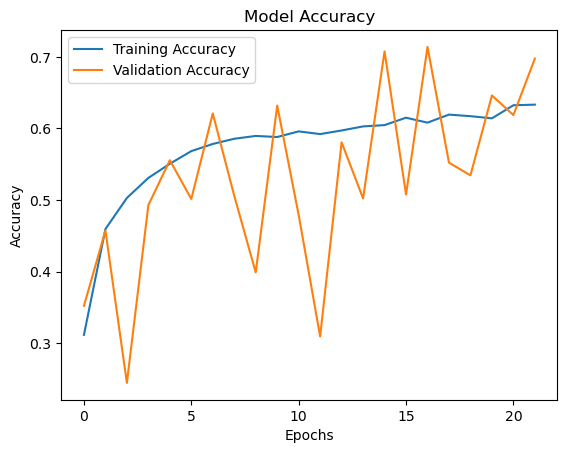

In [64]:
plt.plot(nn_history.history['accuracy'], label='Training Accuracy')
plt.plot(nn_history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

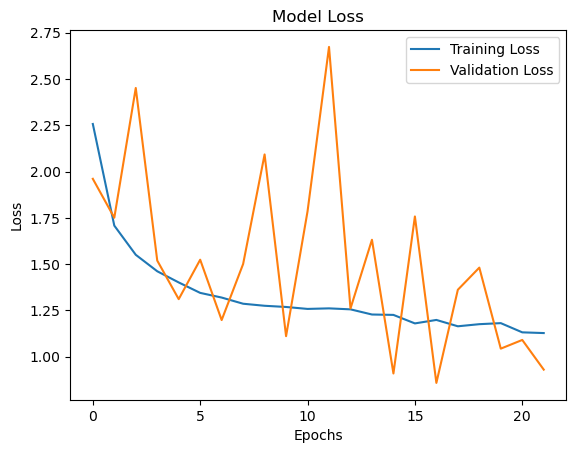

In [65]:
plt.plot(nn_history.history['loss'], label='Training Loss')
plt.plot(nn_history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

In [66]:
andom_idx = np.random.randint(0, len(x_test))
sample = x_test[random_idx]
true_label = np.argmax(y_test[random_idx])

In [67]:
predicted_label = np.argmax(nn_model.predict(np.expand_dims(sample, axis=0)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 691ms/step


In [68]:
print(f"True Label: {true_label}, Predicted Label: {predicted_label}")

True Label: 14, Predicted Label: 14


In [69]:
nn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)                  │ (None, 49152)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 256)                 │      12,583,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_15               │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_15 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_16               │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_16 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_19 (Dense)                     │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_17               │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_17 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_20 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_18               │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_18 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_21 (Dense)                     │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_19               │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_19 (Dropout)                 │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_22 (Dense)                     │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_20               │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 38,328,879 (146.21 MB)

 Trainable params: 12,775,567 (48.73 MB)

 Non-trainable params: 2,176 (8.50 KB)

 Optimizer params: 25,551,136 (97.47 MB)

In [70]:
# الحصول على التوقعات الاحتمالية
y_pred_proba = nn_model.predict(x_test)  

# تحويل التوقعات الاحتمالية إلى قيم ثنائية (0 أو 1) أو القيم الفئوية
y_pred = np.argmax(y_pred_proba, axis=1)  # إذا كان لديك تصنيفات متعددة
y_true = np.argmax(y_test, axis=1)

516/516 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step


In [71]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted') 
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [72]:
print("Evaluation Metrics:")
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-Score: {f1:.2f}")

Evaluation Metrics:
Accuracy: 0.71
Precision: 0.73
Recall: 0.71
F1-Score: 0.70


In [73]:
print("\nClassification Report:")
print(classification_report(y_true, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.47      0.55       818
           1       0.68      0.94      0.79      1207
           2       0.73      0.91      0.81       784
           3       0.00      0.00      0.00       113
           4       0.66      0.39      0.49       787
           5       0.69      0.88      0.77      1704
           6       0.41      0.36      0.39       800
           7       0.89      0.87      0.88      1264
           8       0.63      0.82      0.71      1519
           9       0.74      0.76      0.75       781
          10       0.83      0.47      0.60      1449
          11       0.59      0.84      0.69      1348
          12       0.73      0.66      0.69      1078
          13       0.95      0.35      0.51       295
          14       0.92      0.74      0.82      2563

    accuracy                           0.71     16510
   macro avg       0.67      0.63      0.63     16510
we

F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


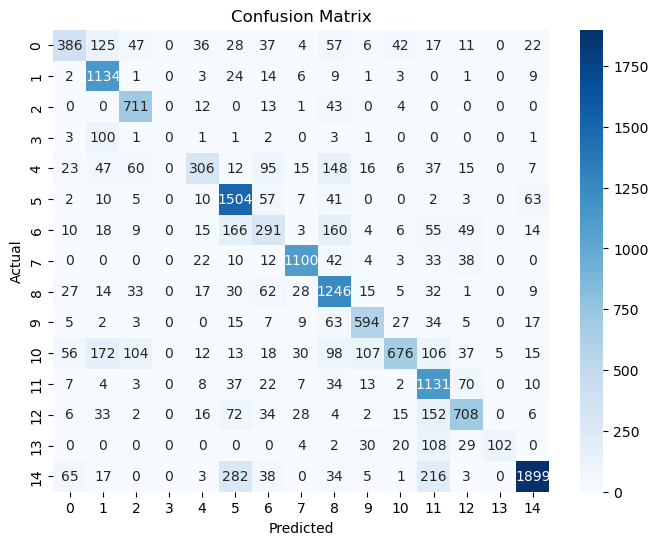

In [74]:
import seaborn as sns
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=range(num_classes), yticklabels=range(num_classes))
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


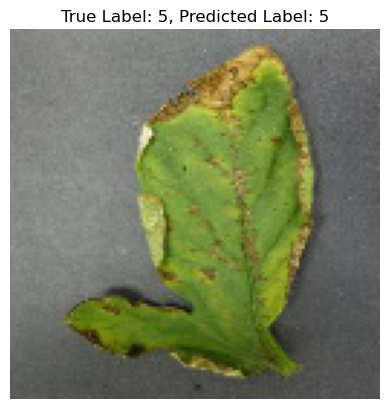

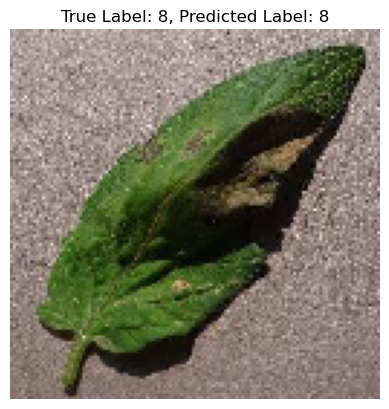

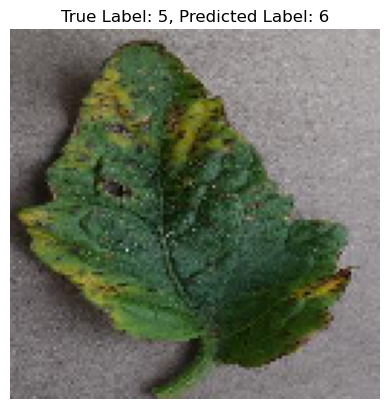

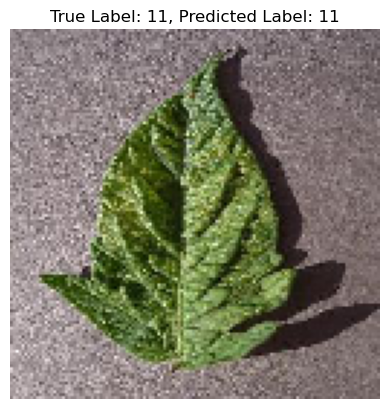

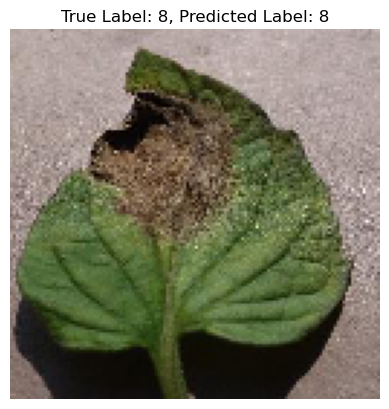

...

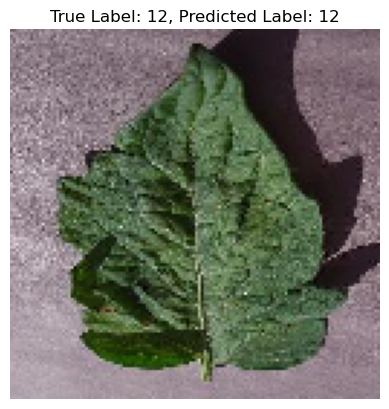

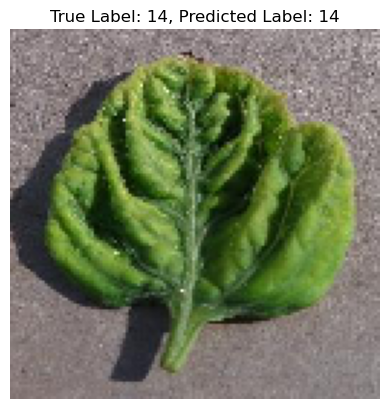

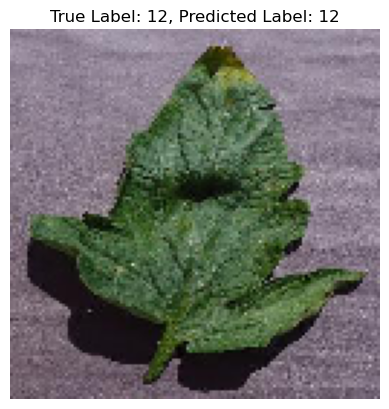

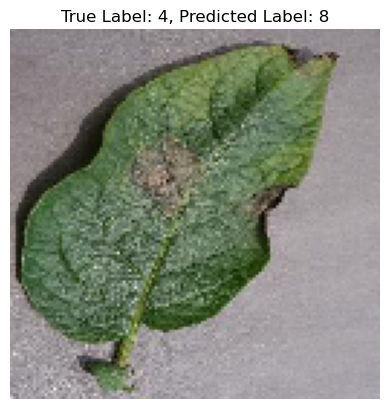

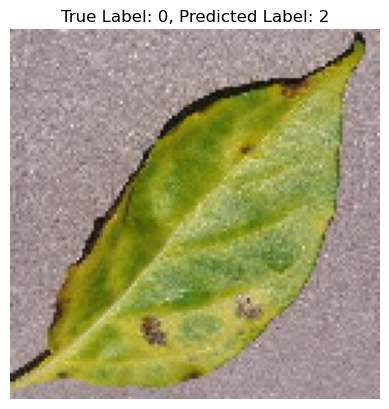

In [75]:
# عدد الصور التي تريد عرضها
num_images_to_display = 15

# اختيار عينات عشوائية من مجموعة الاختبار
random_indices = np.random.choice(len(x_test), num_images_to_display, replace=False)

# التنبؤ باستخدام النموذج
predictions = nn_model.predict(x_test[random_indices])

# عرض الصور مع الفئات الحقيقية والمتوقعة
for i, idx in enumerate(random_indices):
    sample = x_test[idx]
    true_label = np.argmax(y_test[idx])  # إذا كان y_test في صيغة one-hot encoding
    predicted_label = np.argmax(predictions[i])

    # عرض الصورة
    plt.imshow(sample)
    plt.title(f"True Label: {true_label}, Predicted Label: {predicted_label}")
    plt.axis('off')  # إخفاء المحاور
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 339ms/step


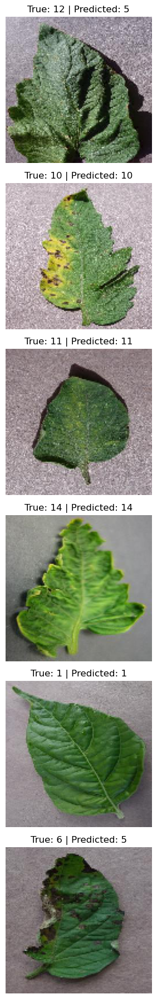

In [76]:
# اختيار إدخالات يدوية (أرقام الصور في x_test)
input_indices = [5, 10,15,20,25,30]  # ضع هنا أرقام الصور التي تريد عرضها

# التحقق من صحة المدخلات
for idx in input_indices:
    if idx >= len(x_test):
        print(f"Index {idx} is out of range! The dataset contains {len(x_test)} samples.")
        exit()

# التنبؤ باستخدام النموذج
predictions = nn_model.predict(x_test[input_indices])

# عرض الصور مع الفئات الحقيقية والفئات المتوقعة
plt.figure(figsize=(10, len(input_indices) * 3))
for i, idx in enumerate(input_indices):
    sample = x_test[idx]
    true_label = np.argmax(y_test[idx])  # إذا كان y_test في صيغة one-hot encoding
    predicted_label = np.argmax(predictions[i])

    # عرض الصورة
    plt.subplot(len(input_indices), 1, i + 1)  # ترتيب الصور في شبكة عمودية
    plt.imshow(sample)
    plt.title(f"True: {true_label} | Predicted: {predicted_label}")
    plt.axis('off')  # إخفاء المحاور

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


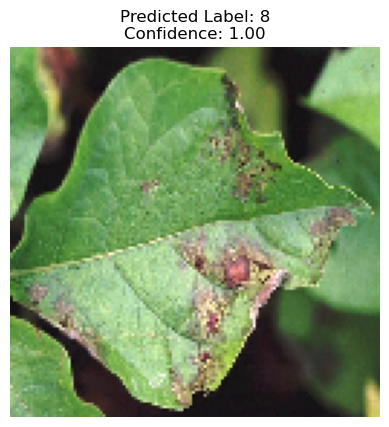

In [77]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import numpy as np
import matplotlib.pyplot as plt

# تحديد مسار الصورة التي تريد اختبارها
image_path = r'Unidentified_disease_on_potato_leaf.jpg'  # عدّل هذا المسار حسب مكان الصورة على جهازك

# إعداد الحجم المطلوب للصورة (يجب أن يتطابق مع حجم الإدخال للنموذج)
img_size = 128  # أو أي حجم حددته في نموذجك

# تحميل الصورة وتغيير حجمها
try:
    img = load_img(image_path, target_size=(img_size, img_size))  # تحميل الصورة بالحجم المناسب
    img_array = img_to_array(img) / 255.0  # تحويل الصورة إلى مصفوفة وتطبيع القيم إلى [0, 1]

    # إضافة بُعد إضافي لجعلها في صيغة (1, img_size, img_size, 3)
    img_array = np.expand_dims(img_array, axis=0)

    # التنبؤ باستخدام النموذج
    prediction = nn_model.predict(img_array)
    predicted_label = np.argmax(prediction)  # اختيار التصنيف الأكثر احتمالاً
    confidence = np.max(prediction)  # درجة الثقة في التوقع

    # عرض الصورة مع الفئة المتوقعة
    plt.imshow(img)
    plt.title(f"Predicted Label: {predicted_label}\nConfidence: {confidence:.2f}")
    plt.axis('off')
    plt.show()

except Exception as e:
    print(f"Error loading or processing image: {e}")

# CNN

In [78]:
x_train, x_test, y_train, y_test = train_test_split(images, labels, test_size=0.2, random_state=42)

# تحويل التسميات إلى one-hot encoding
num_classes = len(set(labels))
y_train = to_categorical(y_train, num_classes)
y_test = to_categorical(y_test, num_classes)

In [79]:
x_train = np.array(x_train)
y_train = np.array(y_train)

In [80]:
print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")

x_train shape: (16510, 128, 128, 3)
y_train shape: (16510, 15)


In [81]:
x_train = np.array(x_train)
y_train = np.array(y_train)

In [82]:
print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")

x_train shape: (16510, 128, 128, 3)
y_train shape: (16510, 15)


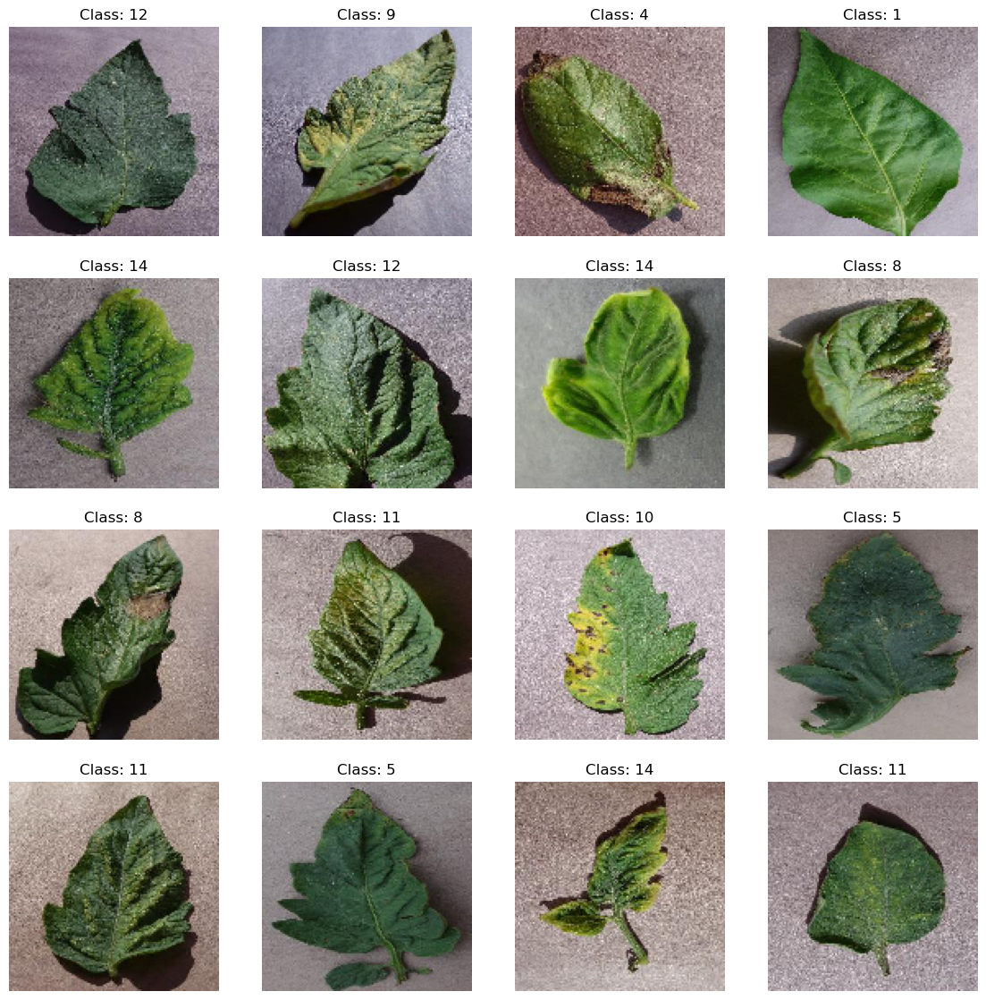

In [83]:
# عرض عينة من الصور
plt.figure(figsize=(14, 14))
for i in range(16):
    plt.subplot(4, 4, i+1)
    plt.imshow(x_train[i])
    plt.title(f"Class: {np.argmax(y_train[i])}")
    plt.axis('off')
plt.show()

In [91]:
cnn_model = Sequential([
    Conv2D(256, (3, 3), activation='relu', input_shape=(128, 128, 3), padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    
    Conv2D(256, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),
    
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(15, activation='softmax')
])

F:\anaconda\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [92]:
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
checkpoint = ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)

# قائمة الـ Callbacks
callbacks = [early_stop, checkpoint]

In [93]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

# التأكد من أن x_train و y_train متطابقين في الطول
print(f"Length of x_train: {len(x_train)}")
print(f"Length of y_train: {len(y_train)}")

# إنشاء المولد
train_generator = datagen.flow(x_train, y_train)

Length of x_train: 16510
Length of y_train: 16510


In [94]:
x_test = np.array(x_train)
y_test = np.array(y_train)

In [95]:
print(x_test.shape)
print(y_test.shape)

(16510, 128, 128, 3)
(16510, 15)


In [96]:
cnn_model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

In [97]:
history = cnn_model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=5,
    batch_size=20,
    callbacks=[early_stop,checkpoint]
)

Epoch 1/5
826/826 ━━━━━━━━━━━━━━━━━━━━ 6283s 8s/step - accuracy: 0.3434 - loss: 2.4563 - val_accuracy: 0.1230 - val_loss: 11.0837
Epoch 2/5
826/826 ━━━━━━━━━━━━━━━━━━━━ 11546s 14s/step - accuracy: 0.5525 - loss: 1.4507 - val_accuracy: 0.6199 - val_loss: 1.0737
Epoch 3/5
826/826 ━━━━━━━━━━━━━━━━━━━━ 6398s 8s/step - accuracy: 0.6401 - loss: 1.1236 - val_accuracy: 0.5455 - val_loss: 3.4638
Epoch 4/5
826/826 ━━━━━━━━━━━━━━━━━━━━ 6367s 8s/step - accuracy: 0.6789 - loss: 0.9759 - val_accuracy: 0.6449 - val_loss: 1.0718
Epoch 5/5
826/826 ━━━━━━━━━━━━━━━━━━━━ 26217s 32s/step - accuracy: 0.7032 - loss: 0.8982 - val_accuracy: 0.3646 - val_loss: 4.2326


In [101]:
test_loss, test_acc = cnn_model.evaluate(x_test, y_test)
print(f"Test Accuracy: {test_acc}")
print(f"Test Loss: {test_loss}")

516/516 ━━━━━━━━━━━━━━━━━━━━ 856s 2s/step - accuracy: 0.6418 - loss: 1.0760
Test Accuracy: 0.6449424624443054
Test Loss: 1.0718131065368652


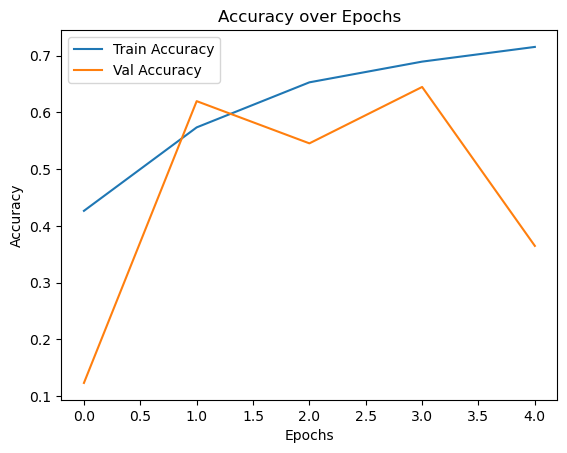

In [102]:
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

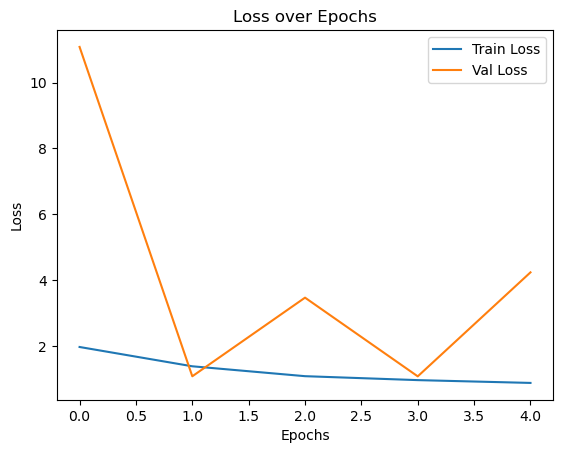

In [103]:
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [104]:
y_pred_proba = cnn_model.predict(x_test)
y_true = np.argmax(y_test, axis=1)

516/516 ━━━━━━━━━━━━━━━━━━━━ 847s 2s/step


In [105]:
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [106]:
print("Evaluation Metrics:")
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-Score: {f1:.2f}")

Evaluation Metrics:
Accuracy: 0.71
Precision: 0.73
Recall: 0.71
F1-Score: 0.70


In [107]:
print("\nClassification Report:")
print(classification_report(y_true, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.47      0.55       818
           1       0.68      0.94      0.79      1207
           2       0.73      0.91      0.81       784
           3       0.00      0.00      0.00       113
           4       0.66      0.39      0.49       787
           5       0.69      0.88      0.77      1704
           6       0.41      0.36      0.39       800
           7       0.89      0.87      0.88      1264
           8       0.63      0.82      0.71      1519
           9       0.74      0.76      0.75       781
          10       0.83      0.47      0.60      1449
          11       0.59      0.84      0.69      1348
          12       0.73      0.66      0.69      1078
          13       0.95      0.35      0.51       295
          14       0.92      0.74      0.82      2563

    accuracy                           0.71     16510
   macro avg       0.67      0.63      0.63     16510
we

F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
F:\anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1509: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


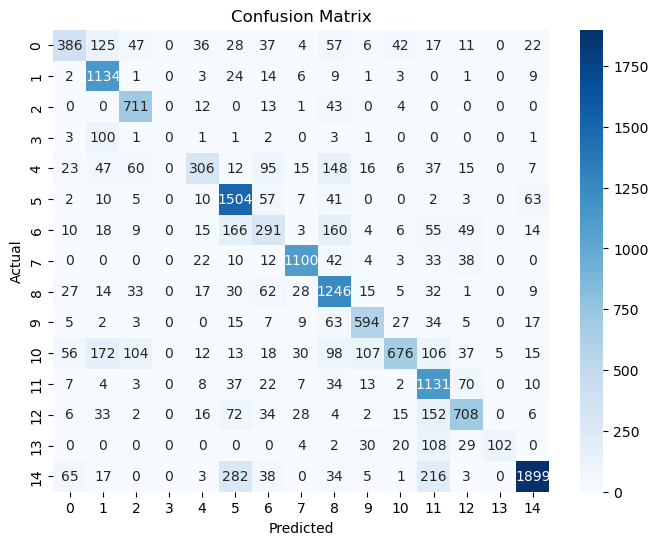

In [108]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=range(num_classes), yticklabels=range(num_classes))
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 820ms/step


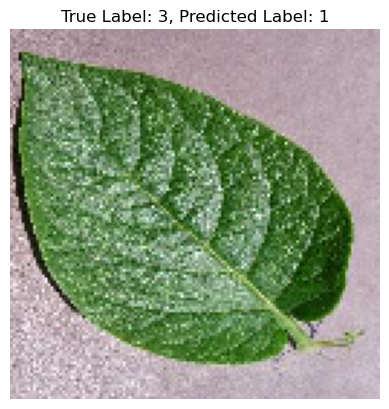

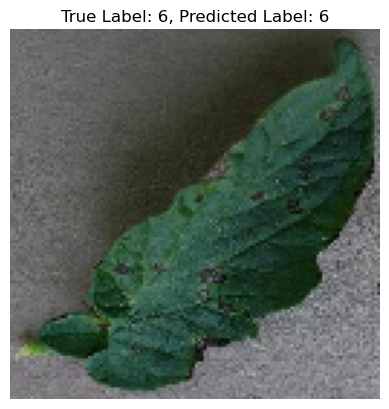

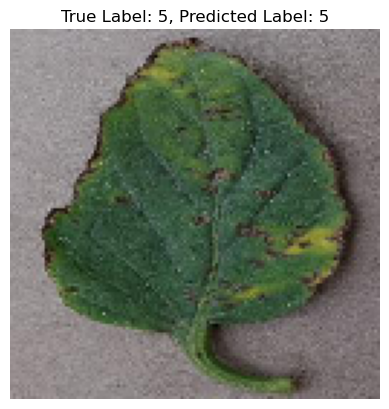

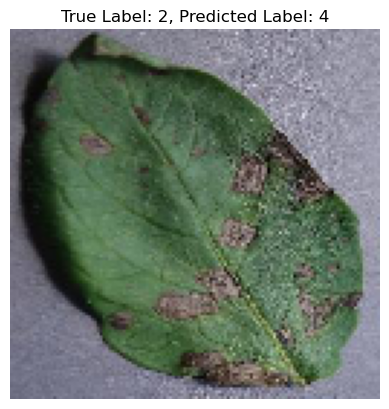

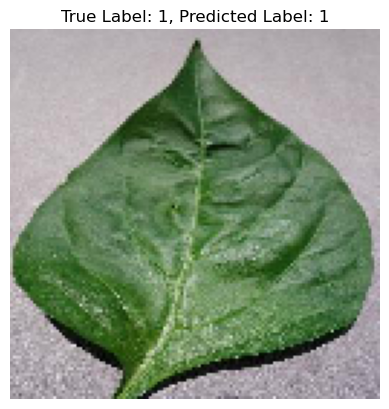

...

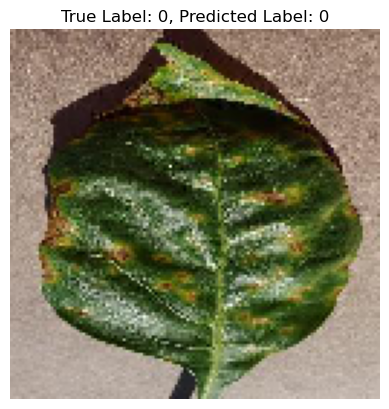

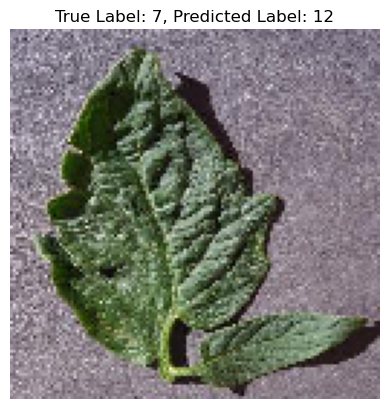

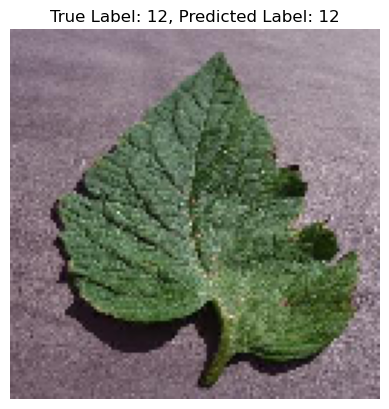

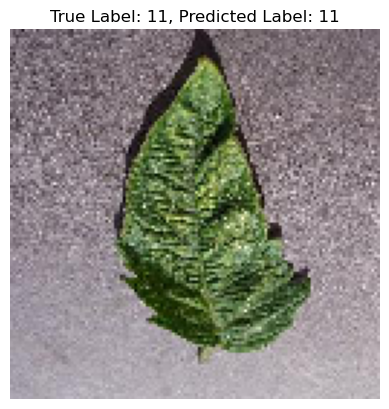

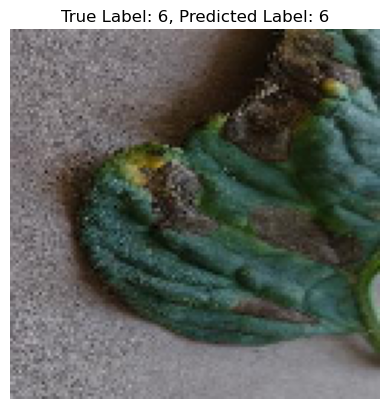

In [109]:
# عدد الصور التي تريد عرضها
num_images_to_display = 15

# اختيار عينات عشوائية من مجموعة الاختبار
random_indices = np.random.choice(len(x_test), num_images_to_display, replace=False)

# التنبؤ باستخدام النموذج CNN
predictions = cnn_model.predict(x_test[random_indices])

# عرض الصور مع الفئات الحقيقية والمتوقعة
for i, idx in enumerate(random_indices):
    sample = x_test[idx]
    true_label = np.argmax(y_test[idx])  # إذا كان y_test في صيغة one-hot encoding
    predicted_label = np.argmax(predictions[i])

    # عرض الصورة
    plt.imshow(sample)  # افتراض أن الصور مُطَبَّعة (values بين 0 و 1)
    plt.title(f"True Label: {true_label}, Predicted Label: {predicted_label}")
    plt.axis('off')  # إخفاء المحاور
    plt.show()
